### Case Study: **Synthetic Data Validation**

*Validating Hades*

[![Documentation](https://img.shields.io/badge/docs-latest-blue?logo=read-the-docs&logoColor=white)](https://hades-obol.readthedocs.io/en/latest/)
[![GitHub](https://img.shields.io/badge/GitHub-Hades-red?logo=github)](https://github.com/Jack6228/Hades)
[![PyPI](https://img.shields.io/pypi/v/hades-obol?logo=pypi&logoColor=white)](https://pypi.org/project/hades-obol/)
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Jack6228/Hades/blob/main/examples/synthetics/synthetics.ipynb)

This dataset serves as an idealised, controlled numerical benchmark designed to evaluate Hades' ability to accurately recover known parameters and reproduce the expected geochemical evolution of a magmatic system.

We create a synthetic data suite by simulating a fractional crystallisation process with a known starting composition and for four phases of crystallisation, add a mineral of fixed composition to the bulk crystallising mineral assemblage at each stage.

Hades should be able to - and does - recover the amount of crystallisation and the mineral proportions for each stage.

> Note: This notebook is not intended to act as a tutorial directly, but to demonstrate this case study. See the [Hades Python Tutorial ↗](https://hades-obol.readthedocs.io/en/latest/api/tutorial.html) for more detailed explanations.

**Key links**: [GitHub Folder ↗](https://github.com/Jack6228/Hades/tree/main/examples/synthetics) | [Documentation Page ↗](https://hades-obol.readthedocs.io/en/latest/case_studies/synthetics/index.html) | [API Reference ↗](https://hades-obol.readthedocs.io/en/latest/api/index.html)

---

**Model Setup**

In [1]:
# Import the Obol class from the hades module and initialise a new model
from hades import Obol
model = Obol.newModel()

# Load the synthetic data suite
model.load_data_suite('./synthetics.csv')

# Select samples to form the projected LLOD
model.select_initial_composition(['Primary', 'Primitive', 'Basic', 'Intermediate', 'Evolved', None])

hades-obol v0.8.4. This is a pre-release version. Check for updates using hades.check_for_updates()


Primary       : 'Primary'
Primitive     : 'Primitive'
Basic         : 'Basic'
Intermediate  : 'Intermediate'
Evolved       : 'Evolved'
End           : n/a
5/6 phases have been set with user-provided initial compositions.


**Customisation**

Here, we can configure KD values, contributing minerals and their compositions

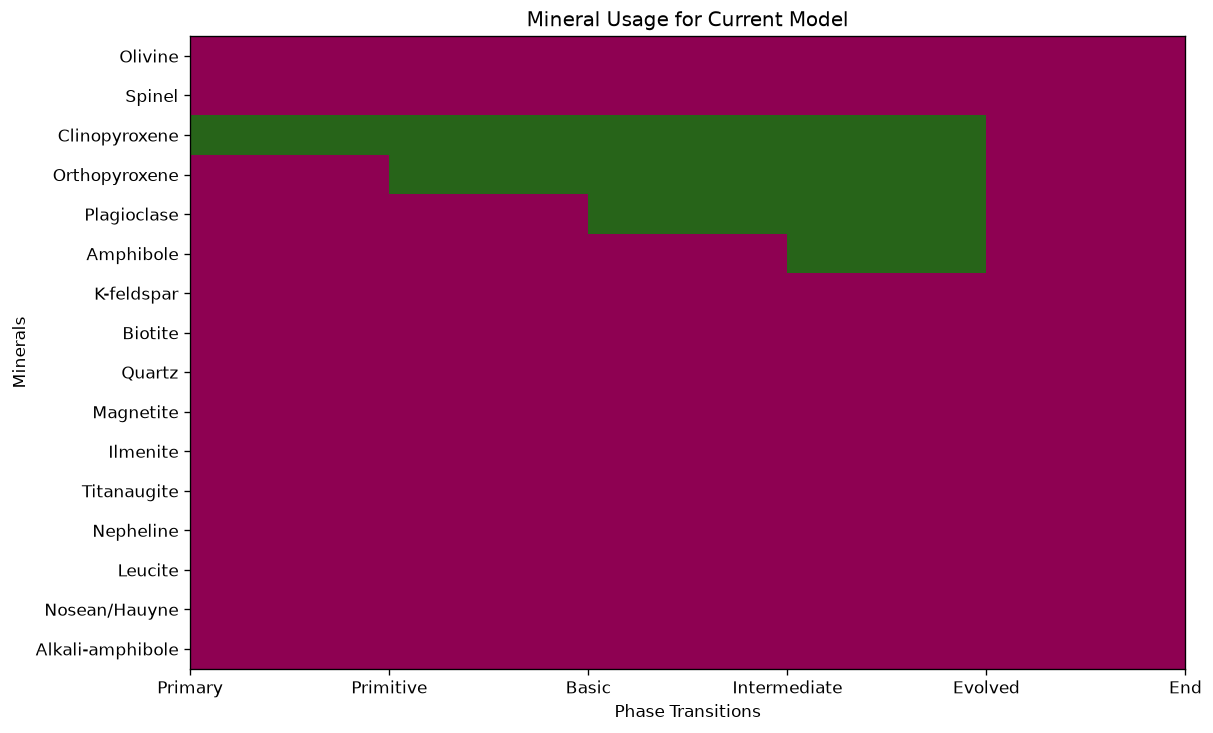

In [2]:
# Define which minerals contribute to the assemblage and in which phases
model.set_mineral_usage(
    __=False,
    __cpx=True,
    primitive__opx=True,
    basic__opx=True,
    intermediate__opx=True,
    basic__plagioclase=True,
    intermediate__plagioclase=True,
    intermediate__amphibole=True,
)

# Optionally: view the mineral usage configuration
from hades.visuals import mineral_usage
mineral_usage(
    model,
    filename='./outputs/mineral_usage.png',
)

In [3]:
# Specify the mineralogical compositions for minerals and phases (in wt.%)
model.set_mineralogies(
    __cpx=[40, 0.25, 1, 17, 40, 1.25, 0.25, 0.25],
    __opx=[48, 1, 6, 10, 14, 19.5, 1, 0.5],
    __plagioclase=[50, 0, 31, 0, 0, 16, 2.5, 0.5],
    __amphibole=[0, 5, 0, 95, 0, 0, 0, 0]
)

We increase the population size and maximum number of generations in order to provide sufficient time for the algorithm to converge on the expected solution in these simple examples. This is also important since each phase continues from the melt composition arising from the previous phase's optimised result.

We also adjust the optimisation bounds to ensure that the algorithm can explore the full range of possible mineralogies, since these synthetic examples may not adhere to the physical constraints of natural systems which Hades accounts for.

In [4]:
model.optimising.pop_size = 100
model.optimising.max_iter = 5000
model.optimising.bounds = [[0,1]] * 12

# Save the config file for later use or use in the Windows Application
model.save_config("./synthetics.hades")

Successfully saved configuration to ./synthetics.hades


**Optimisation**

----

**1 Mineral**

The primary to primitive transition was modelled as a **100 wt.% cpx** magma undergoing **15% fractional crystallisation**. The model should be able to find this solution easily, since there are only two unknowns.

In [5]:
# Run stage 1 (priamry to primitive)
model.run(1)
# Quick access to the solution
model.results[0].solution

> Optimisation completed with cost = 0.00 after 128/5000 iters and 129 func. evals with population size 100 because of: 'Optimization terminated successfully.'


{'FC%': 15.0, 'clinopyroxene': 100.0}

**2 Minerals**

The primitive to basic transition continues from the 1-mineral solution and uses the following parameters: 

| FC% | cpx (wt.%) | opx (wt.%) |
|-----|------------|------------|
| 20  | 25         | 75         |

In [6]:
model.run(2)
model.results[1].solution

> Optimisation completed with cost = 0.00 after 2394/5000 iters and 2395 func. evals with population size 100 because of: 'Optimization terminated successfully.'


{'FC%': 20.0, 'clinopyroxene': 25.0, 'orthopyroxene': 75.0}

**3 Minerals**

For the basic to intermediate transition: 

| FC% | cpx (wt.%) | opx (wt.%) | plag (wt.%) |
|-----|------------|------------|-------------|
| 25  | 10         | 45         | 45          |

In [7]:
model.run(3)
model.results[2].solution

> Optimisation completed with cost = 0.00 after 5000/5000 iters and 5001 func. evals with population size 100 because of: 'Maximum number of iterations has been exceeded.'


{'FC%': 25.0,
 'clinopyroxene': 10.0,
 'orthopyroxene': 45.0,
 'plagioclase': 45.0}

**4 Minerals**

Finally, the intermediate to evolved transition uses: 

| FC% | cpx (wt.%) | opx (wt.%) | plag (wt.%) | amph (wt.%) |
|-----|------------|------------|-------------|-------------|
| 30  | 2.5         | 40         | 40          | 17.5        |

In [8]:
model.run(4)
model.results[3].solution

> Optimisation completed with cost = 0.00 after 5000/5000 iters and 5001 func. evals with population size 100 because of: 'Maximum number of iterations has been exceeded.'


{'FC%': 30.0,
 'clinopyroxene': 2.495,
 'orthopyroxene': 40.002,
 'plagioclase': 40.003,
 'amphibole': 17.5}

At four minerals, the model is able to find a solution that is very close to the expected result, but not exact. This exposes the increasing complexity of the optimisation problem as more parameters are added.

It also highlights Hades' ability to find an optimal solution, even if it is not the true result.

We can also view the results from the entire model:

In [9]:
model.summary()

                        p-P        P-B        B-I        I-E     |     Total   
------------------------------------------------------------------------------------------------
            Type  |    Majors     Majors     Majors     Majors   |            
            Cost  |      0.00       0.00       0.00       0.00   |            
------------------------------------------------------------------------------------------------
               F  |        15         20         25         30   |       100    %
         Olivine  |                                              |              wt.%
          Spinel  |                                              |              wt.%
   Clinopyroxene  |   100.000     25.000     10.000      2.495   |    33.175    wt.%
   Orthopyroxene  |               75.000     45.000     40.002   |    41.245    wt.%
     Plagioclase  |                          45.000     40.003   |    21.416    wt.%
       Amphibole  |                                     17.50

We can visualise the result of the optimisation on bivariate plots and see the optimised LLOD matches that of the initial synthetic data. The model has successfully found the expected solution.

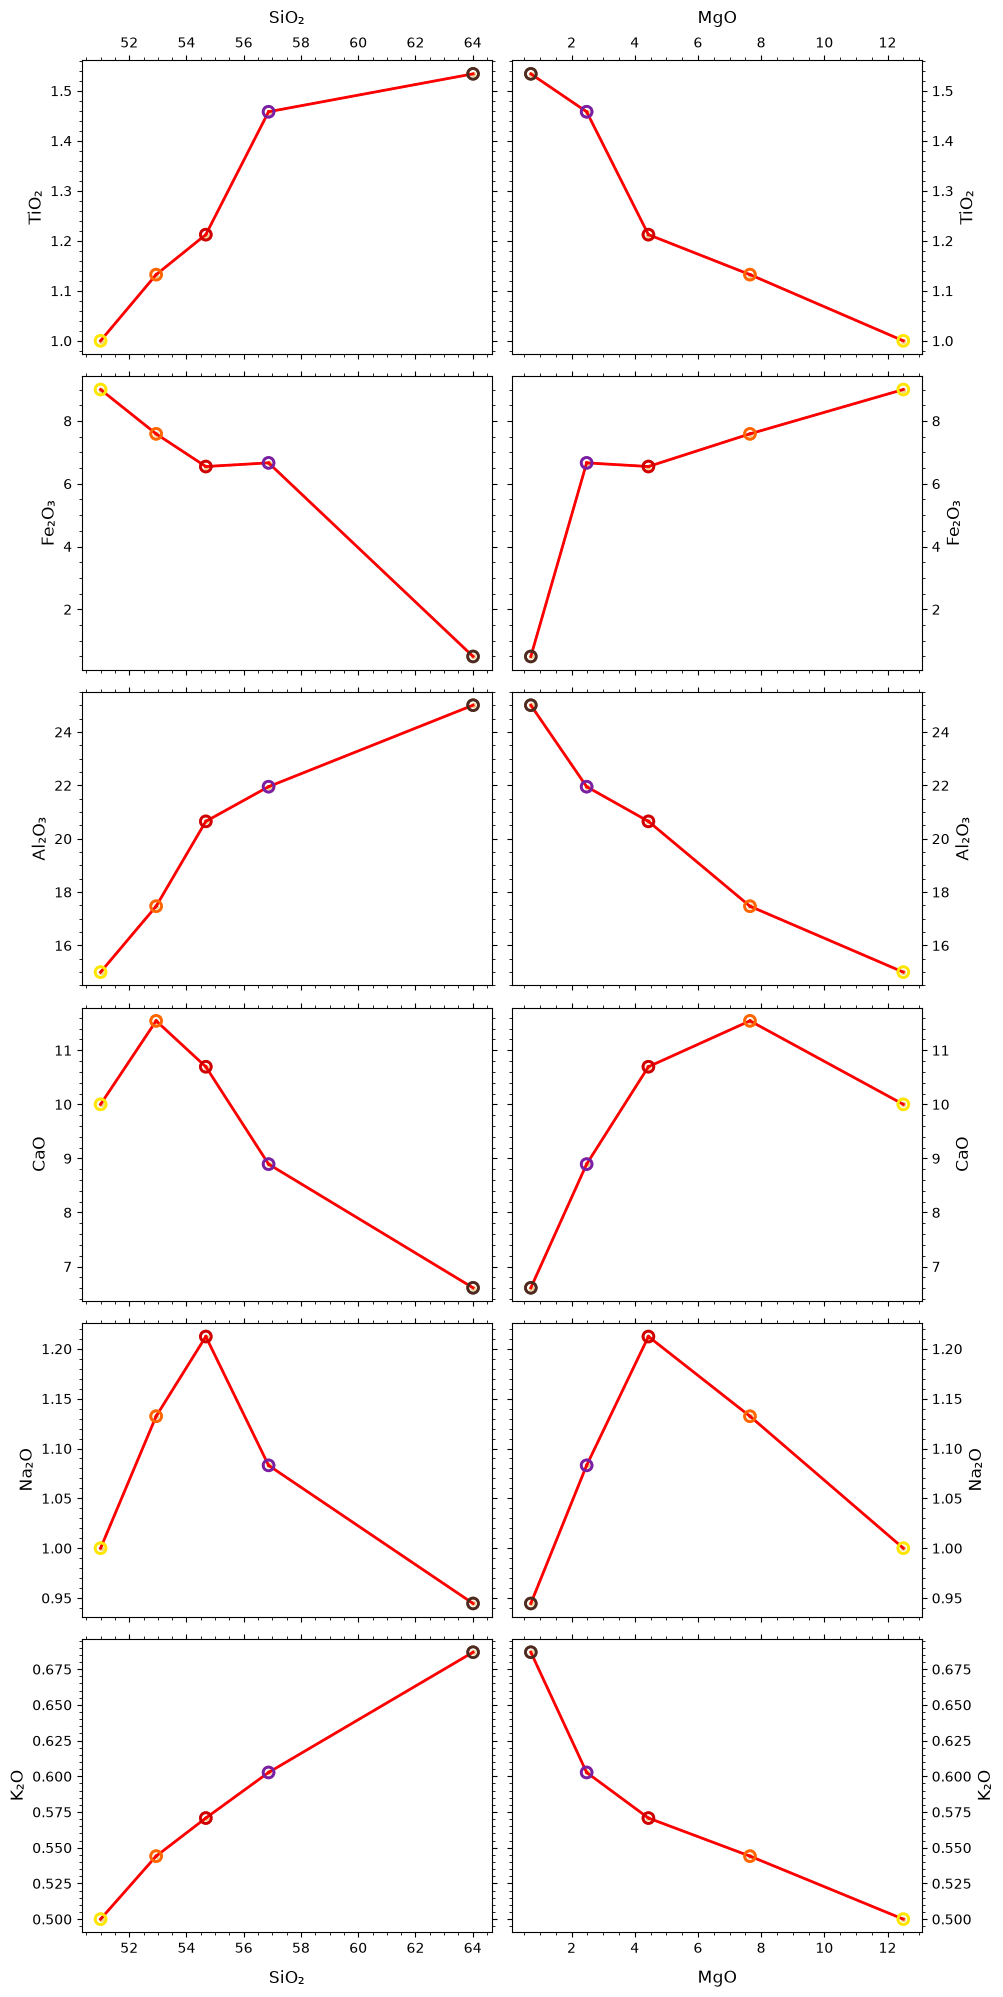

In [10]:
# Plot bivariate plots for the major oxides
from hades.visuals import bivar
bivar(
    model, 
    y_order=['TiO2', 'Fe2O3', 'Al2O3', 'CaO', 'Na2O', 'K2O'], 
    filename='./outputs/bivariate_plots.png',
)

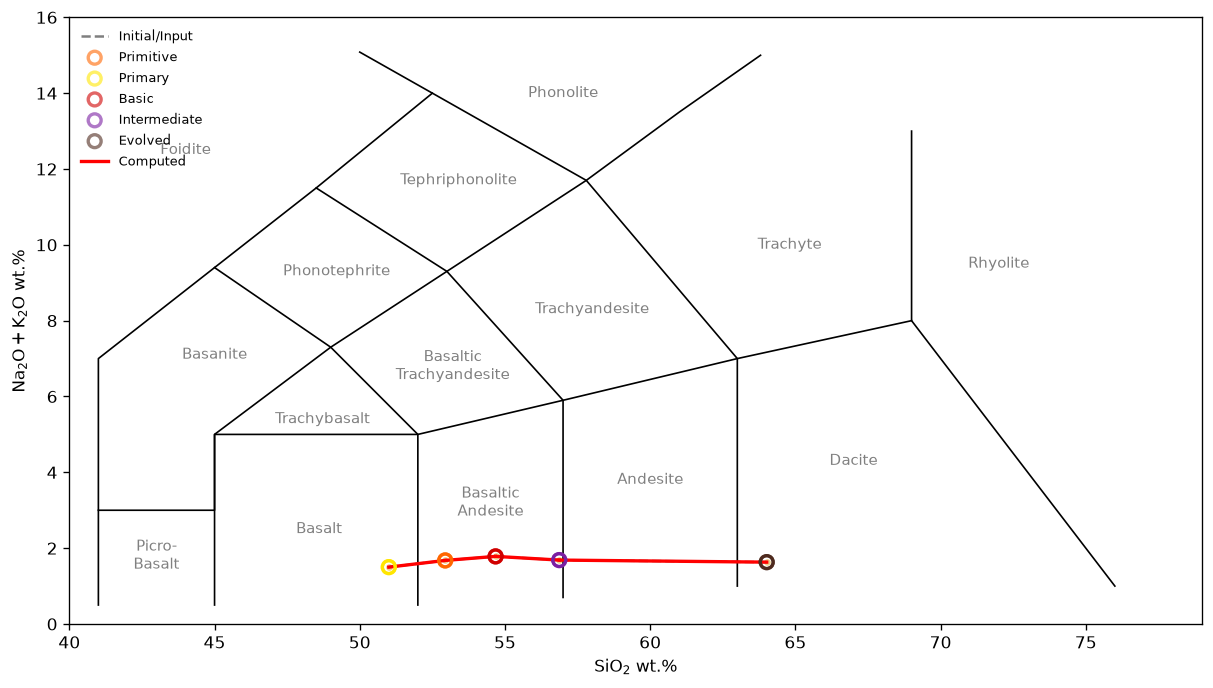

In [11]:
# Plot the TAS diagram and save to a file
from hades.visuals import tas
tas(
    model, 
    filename='./outputs/tas_diagram.png'
)

**Export Results**

In [12]:
model.savePDF('./outputs/results.pdf')
model.saveData('./outputs/data_output.xlsx')

PDF compilation completed. Output saved to ./outputs/results.pdf
Excel file saved successfully: ./outputs/data_output.xlsx


----

**Useful Commands**

Configuration Files

Having saved the configuration to a ``.hades`` file, we can easily reload the model configuration in the future (either in Python or the Hades Windows application) without having to re-import data or reconfigure parameters like mineral contributions and compositions.

See the documentation for more information on [saving and loading model configurations](https://hades-obol.readthedocs.io/en/latest/user_manual/config_files.html).

To use a ``.hades`` configuration file to initialise a model, simply create a fresh model and call the ``load_config`` method with the path to the configuration file. This will automatically import the data and set all parameters as specified in the configuration file, overwriting any arguments passed to the ``newModel`` method.

In [13]:
model = Obol.newModel()
model.load_config('./synthetics.hades')